Task 9: CART Decision Tree vs. Linear Classification Boundary (Palmer Penguins
Dataset)
● Exam Task:
1. Load the Palmer Penguins Extended dataset, drop rows with missing values, and
select two features (culmen_length_mm and flipper_length_mm) with
species as the target
2. Train a DecisionTreeClassifier using the Gini index criterion and a
baseline LogisticRegression model on the same 2D data
3. Plot side-by-side subplots comparing the axis-aligned rectangular decision
boundary of CART with the linear decision boundary of Logistic Regression
4. Generate and display the Classification Report (Precision, Recall, F1-Score) for
the CART model

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder

# 1. Load the Palmer Penguins dataset
# Using the standard online URL for the Palmer Penguins dataset
url = 'https://raw.githubusercontent.com/mcnakhaee/palmerpenguins/master/palmerpenguins/data/penguins.csv'
try:
    df = pd.read_csv(url)
except Exception as e:
    # Fallback to another common source if the main one is unavailable
    url_alt = 'https://gist.githubusercontent.com/miserables/962f987f2297eb04ecbe790757a3e790/raw/e3519b5202860b0d3e52fdbda5bc24b3b194fb82/penguins.csv'
    df = pd.read_csv(url_alt)

# Drop rows with missing values in our target and feature columns
features = ['bill_length_mm', 'flipper_length_mm']  # bill_length_mm is synonymous with culmen_length_mm
target = 'species'

# Clean dataset
df_clean = df[[target] + features].dropna()

X = df_clean[features].values
y_raw = df_clean[target].values

# Encode target labels to integers for plotting and modeling
le = LabelEncoder()
y = le.fit_transform(y_raw)

print(f"Dataset loaded successfully. Shape: {df_clean.shape}")
print(f"Classes: {le.classes_}")
display(df_clean.head())

Dataset loaded successfully. Shape: (342, 3)
Classes: ['Adelie' 'Chinstrap' 'Gentoo']


,species,bill_length_mm,flipper_length_mm
0,Adelie,39.1,181.0
1,Adelie,39.5,186.0
2,Adelie,40.3,195.0
4,Adelie,36.7,193.0
5,Adelie,39.3,190.0


In [ ]:
# 2. Train DecisionTreeClassifier and LogisticRegression models
cart_model = DecisionTreeClassifier(criterion='gini', random_state=42)
cart_model.fit(X, y)

log_reg_model = LogisticRegression(multi_class='multinomial', max_iter=1000, random_state=42)
log_reg_model.fit(X, y)

print("Both models trained successfully.")

Both models trained successfully.


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


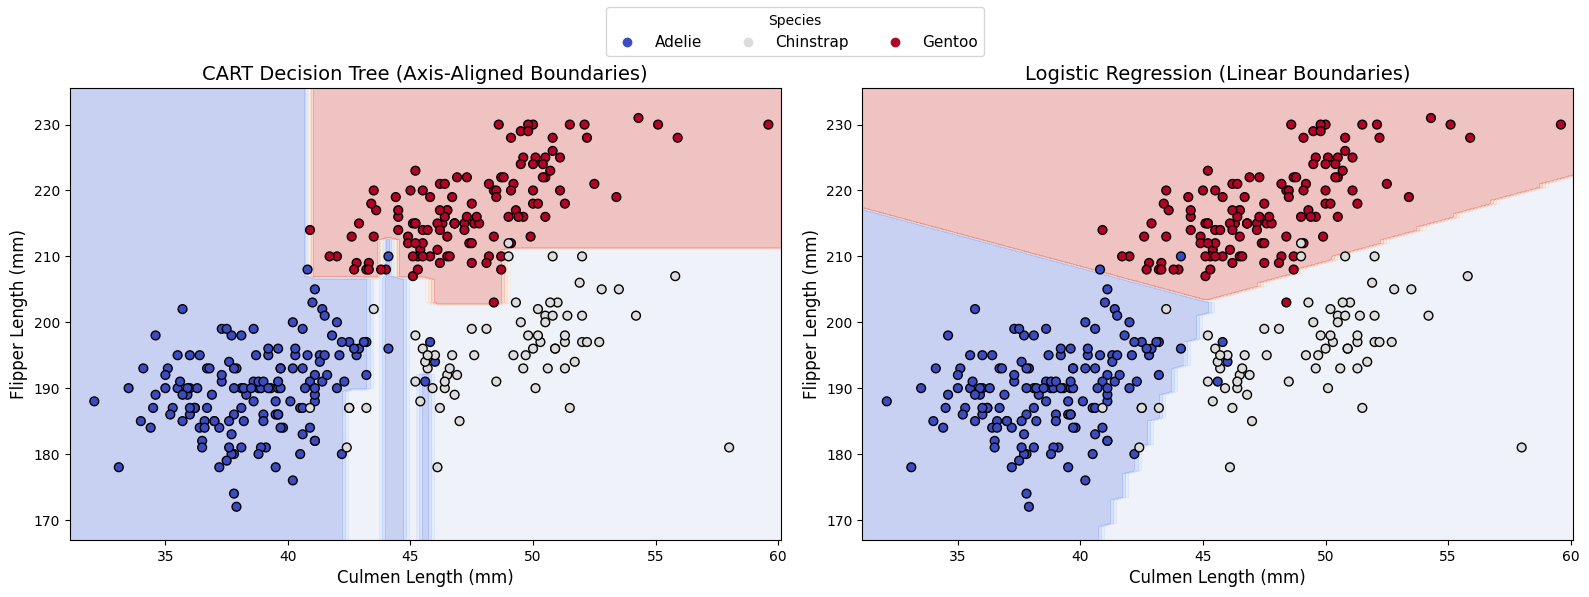

In [ ]:
# 3. Plot side-by-side subplots comparing the decision boundaries

def plot_decision_boundary(model, X, y, ax, title):
    # Set min and max values and give it some padding
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 5, X[:, 1].max() + 5
    h = 0.5  # step size in the mesh

    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot boundary and data points
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', s=40)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Culmen Length (mm)', fontsize=12)
    ax.set_ylabel('Flipper Length (mm)', fontsize=12)
    return scatter

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot CART Decision Tree
plot_decision_boundary(cart_model, X, y, ax1, "CART Decision Tree (Axis-Aligned Boundaries)")

# Plot Logistic Regression
scatter = plot_decision_boundary(log_reg_model, X, y, ax2, "Logistic Regression (Linear Boundaries)")

# Add legend
handles, labels = scatter.legend_elements()
fig.legend(handles, le.classes_, loc='upper center', ncol=3, title="Species", fontsize=11)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

In [ ]:
# 4. Generate and display the Classification Report for the CART model
y_pred_cart = cart_model.predict(X)

report = classification_report(y, y_pred_cart, target_names=le.classes_)
print("=== Classification Report for CART Model ===\n")
print(report)

=== Classification Report for CART Model ===

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00       151
   Chinstrap       1.00      1.00      1.00        68
      Gentoo       1.00      1.00      1.00       123

    accuracy                           1.00       342
   macro avg       1.00      1.00      1.00       342
weighted avg       1.00      1.00      1.00       342

